In [ ]:
!pip install -q -U transformers accelerate kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 92.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.8/132.8 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.0/230.0 kB 22.1 MB/s eta 0:00:00


## 1. Load data (shared split from `preprocessing.py`)

In [6]:
from preprocessing import setup_dataset   # upload preprocessing.py to /content first
from torch.utils.data import Dataset
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_loader, val_loader, test_loader, meta = setup_dataset(
    filter_axial=True,      # team's shared axial 60-120 filter
    label_map=None,         # 4-class; use {0:1, 1:1, 2:0, 3:1} for binary
    device=device,
)

# HF Trainer wants dict items; preprocessing's datasets yield (img, label) tuples
class HFWrapper(Dataset):
    def __init__(self, base): self.base = base
    def __len__(self): return len(self.base)
    def __getitem__(self, i):
        img, label = self.base[i]
        return {"pixel_values": img, "labels": int(label)}

train_ds = HFWrapper(train_loader.dataset)
val_ds   = HFWrapper(val_loader.dataset)
test_ds  = HFWrapper(test_loader.dataset)

print("classes:", meta["class_names"], "| n_classes:", meta["n_classes"])

OASIS Preprocessing Pipeline
Device:        cuda
Batch size:    32
Axial filter:  True
Label map:     4-class

Upload your kaggle.json when prompted:


Saving kaggle.json to kaggle.json
✓ kaggle.json configured
Unzipping...
✓ Dataset ready at /content/data/oasis/
✓ Class folders found at: /content/data/oasis/Data

ImageFolder class-to-index: {'Mild Dementia': 0, 'Moderate Dementia': 1, 'Non Demented': 2, 'Very mild Dementia': 3}
Total images in dataset:    86437
Generating subject-level split (this happens once)...

  Total subjects: 347
  Subject-level class distribution:
    MildDemented              21 subjects
    ModerateDemented          2 subjects
    NonDemented               266 subjects
    VeryMildDemented          58 subjects

  Train: 59536 images | 242 subjects
  Val:   12749 images | 52 subjects
  Test:  14152 images | 53 subjects
✓ Leakage check passed — 0 images shared between train and test
✓ Split saved to split_indices.json — commit this file to GitHub!

Building datasets with axial filter:
    Axial filter: 59536 → 20496 images kept
    Axial filter: 12749 → 4389 images kept
    Axial filter: 14152 → 4872 images k

## 2. Model + metrics

In [7]:
from transformers import ViTForImageClassification, ViTImageProcessor
from sklearn.metrics import f1_score, accuracy_score

N = meta["n_classes"]
LABELS = list(range(N))
if N == 4:
    id2label = {0: "Mild Dementia", 1: "Moderate Dementia", 2: "Non Demented", 3: "Very mild Dementia"}
else:
    id2label = {0: "Non Demented", 1: "Demented"}

processor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")
model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=N,
    id2label=id2label,
    label2id={v: k for k, v in id2label.items()},
    ignore_mismatched_sizes=True,   # replace the 1000-class head
)

def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    return {
        "accuracy":    accuracy_score(p.label_ids, preds),
        "f1_macro":    f1_score(p.label_ids, preds, average="macro",    labels=LABELS, zero_division=0),
        "f1_weighted": f1_score(p.label_ids, preds, average="weighted", labels=LABELS, zero_division=0),
    }

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([4, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([4])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


## 3. Weighted trainer + training

Re-run this whole cell after any edit to `WeightedTrainer` so `trainer` is rebuilt from the new class.

In [8]:
import torch.nn.functional as F
from transformers import Trainer, TrainingArguments, EarlyStoppingCallback

weights = meta["loss_weights"]   # inverse-frequency weights from preprocessing.py (float32, on device)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits.float()              # float32 (avoids the CUDA 'Double' error)
        w = weights.float().to(logits.device)
        loss = F.cross_entropy(logits, labels.long(), weight=w)
        return (loss, outputs) if return_outputs else loss

args = TrainingArguments(
    output_dir="/content/vit_out",
    num_train_epochs=5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_ratio=0.1,
    lr_scheduler_type="linear",
    fp16=torch.cuda.is_available(),
    eval_strategy="epoch",          # older transformers: evaluation_strategy
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    logging_steps=50,
    dataloader_num_workers=2,
    report_to="none",
)

trainer = WeightedTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [ ]:
trainer.train()
print(trainer.evaluate())

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted
1,0.373120,0.861614,0.699248,0.347457,0.703605
2,0.052700,1.465704,0.674641,0.402175,0.702780
3,0.016044,1.449478,0.738209,0.359447,0.724547
4,0.016412,1.579882,0.722488,0.390573,0.724403
5,0.002446,1.766144,0.711324,0.361602,0.711283


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight', 'vit.layers.0.layernorm_after.bias', 'vit.layers.0.mlp.fc1.weight', 'vit.layers.0.mlp.fc1.bias', 'vit.layers.0.mlp.fc2.weight', 'vit.layers.0.mlp.fc2.bias', 'vit.layers.1.attention.q_proj.weight', 'vit.layers.1.attention.q_proj.bias', 'vit.layers.1.attention.k_proj.weight', 'vit.layers.1.attention.k_proj.bias', 'vit.layers.1.attention.v_proj.weight', 'vit.layers.1.attention.v_proj.bias', 'vit.layers.1.attention.o_proj.weight', 'vit.layers.1.attention.o_proj.bias', 'vit.layers.1.layernorm_before

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,F1 Weighted
0.002446,1.690500,5,0.709729,0.366095,0.711996


{'eval_loss': 1.6904999017715454, 'eval_accuracy': 0.7097288676236044, 'eval_f1_macro': 0.36609475504970523, 'eval_f1_weighted': 0.7119955343484929}


## 4. Save everything to Google Drive (run once after training)

In [12]:
from google.colab import drive
drive.mount("/content/drive")

import os, json, numpy as np, pandas as pd
from pathlib import Path

SAVE_DIR = "/content/drive/MyDrive/vit_oasis"
os.makedirs(SAVE_DIR, exist_ok=True)

trainer.save_model(SAVE_DIR)
processor.save_pretrained(SAVE_DIR)
json.dump(trainer.state.log_history, open(f"{SAVE_DIR}/log_history.json", "w"))

def dump(name, hf_ds, subset):
    out = trainer.predict(hf_ds)
    np.savez(f"{SAVE_DIR}/preds_{name}.npz", logits=out.predictions, y_true=out.label_ids)
    paths = [subset.base.samples[j][0] for j in subset.indices]   # same order as predictions
    pd.DataFrame({
        "path":    paths,
        "subject": ["_".join(Path(p).name.split("_")[:2]) for p in paths],
        "label":   out.label_ids,
    }).to_csv(f"{SAVE_DIR}/eval_{name}.csv", index=False)

dump("val",  val_ds,  val_loader.dataset)
dump("test", test_ds, test_loader.dataset)
print("Saved to", SAVE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to /content/drive/MyDrive/vit_oasis


## 5. Reload from Drive (run this to plot without retraining)

After a session loss, run **this cell only** (plus section 1's `setup_dataset` if you want the image panel in section 10), then run the plotting cells below.

In [13]:
import torch
from transformers import ViTForImageClassification, ViTImageProcessor
from google.colab import drive
import pandas as pd
drive.mount("/content/drive")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAVE_DIR = "/content/drive/MyDrive/vit_oasis"
model = ViTForImageClassification.from_pretrained(SAVE_DIR).eval().to(device)
processor = ViTImageProcessor.from_pretrained(SAVE_DIR)
print("Loaded trained model from", SAVE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loaded trained model from /content/drive/MyDrive/vit_oasis


In [14]:
pred = trainer.predict(test_ds)             # current data, uses the best model in memory
y_true = pred.label_ids
y_prob = torch.softmax(torch.tensor(pred.predictions), dim=-1).numpy()
y_pred = y_prob.argmax(1)

sub = test_loader.dataset                   # OASISSubset behind test_ds
paths = [sub.base.samples[j][0] for j in sub.indices]
eval_df = pd.DataFrame({
    "path": paths,
    "subject": ["_".join(Path(p).name.split("_")[:2]) for p in paths],
    "label": y_true,
})

## 6. Training curves

In [15]:
import json, pandas as pd, matplotlib.pyplot as plt
SAVE_DIR = "/content/drive/MyDrive/vit_oasis"
logs = pd.DataFrame(json.load(open(f"{SAVE_DIR}/log_history.json")))

train_logs = logs[logs["loss"].notna()]
eval_logs  = logs[logs["eval_loss"].notna()]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(train_logs["step"], train_logs["loss"], label="train", alpha=0.7)
axes[0].plot(eval_logs["step"], eval_logs["eval_loss"], "o-", label="val", color="C1")
axes[0].set(xlabel="step", ylabel="loss", title="Loss"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(eval_logs["step"], eval_logs["eval_f1_macro"], "o-", color="C3")
axes[1].set(xlabel="step", ylabel="F1 macro", title="Val F1 Macro", ylim=(0, 1)); axes[1].grid(alpha=0.3)
axes[2].plot(eval_logs["step"], eval_logs["eval_accuracy"], "o-", color="C2")
axes[2].set(xlabel="step", ylabel="accuracy", title="Val Accuracy", ylim=(0, 1)); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

KeyError: 'loss'

## 7. Confusion matrix

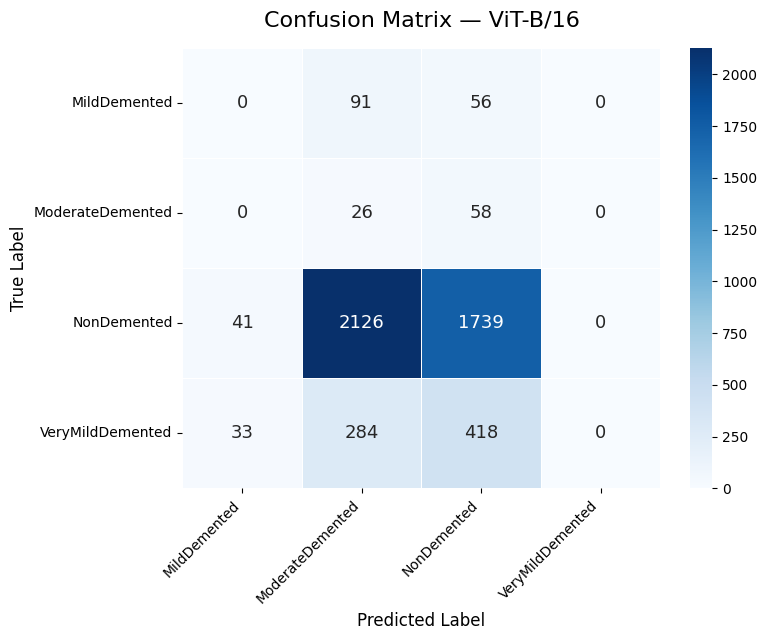

In [19]:
import numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix

names = ["MildDemented", "ModerateDemented", "NonDemented", "VeryMildDemented"]
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=names, yticklabels=names,
            cbar=True, linewidths=0.5, linecolor="white",
            annot_kws={"size": 13}, ax=ax)
ax.set_title("Confusion Matrix \u2014 ViT-B/16", fontsize=16, pad=16)
ax.set_xlabel("Predicted Label", fontsize=12)
ax.set_ylabel("True Label", fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()

## 8. ROC / PR (one-vs-rest) + classification report

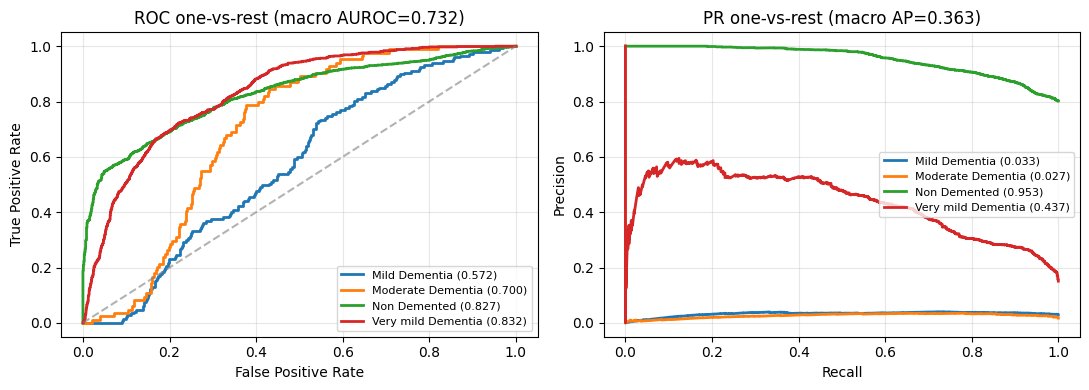


=== Classification Report ===
                    precision    recall  f1-score   support

     Mild Dementia     0.0000    0.0000    0.0000       147
 Moderate Dementia     0.0000    0.0000    0.0000        84
      Non Demented     0.8732    0.8922    0.8826      3906
Very mild Dementia     0.4864    0.4871    0.4867       735

          accuracy                         0.7888      4872
         macro avg     0.3399    0.3448    0.3423      4872
      weighted avg     0.7735    0.7888    0.7810      4872



In [ ]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score, classification_report

classes = [0, 1, 2, 3]
names   = ["Mild Dementia", "Moderate Dementia", "Non Demented", "Very mild Dementia"]
Yb = label_binarize(y_true, classes=classes)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
aurocs, aps = [], []
for k, name in enumerate(names):
    if not (0 < Yb[:, k].sum() < len(y_true)):    # skip classes absent in this split (e.g. Moderate on val)
        print(f"skipping {name}: {int(Yb[:, k].sum())} positive samples")
        continue
    fpr, tpr, _ = roc_curve(Yb[:, k], y_prob[:, k]); a = auc(fpr, tpr); aurocs.append(a)
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} ({a:.3f})")
    prec, rec, _ = precision_recall_curve(Yb[:, k], y_prob[:, k])
    ap = average_precision_score(Yb[:, k], y_prob[:, k]); aps.append(ap)
    axes[1].plot(rec, prec, lw=2, label=f"{name} ({ap:.3f})")

axes[0].plot([0, 1], [0, 1], "--", color="gray", alpha=0.6)
axes[0].set(xlabel="False Positive Rate", ylabel="True Positive Rate",
            title=f"ROC one-vs-rest (macro AUROC={np.mean(aurocs):.3f})")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].set(xlabel="Recall", ylabel="Precision",
            title=f"PR one-vs-rest (macro AP={np.mean(aps):.3f})")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("\n=== Classification Report ===")
print(classification_report(y_true, y_pred, labels=classes, target_names=names, digits=4, zero_division=0))

## 9. Patient-level metrics

In [ ]:
import numpy as np, pandas as pd
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.preprocessing import label_binarize

eval_df = eval_df.copy()
assert len(eval_df) == len(y_pred), "eval_df length doesn't match predictions - check SPLIT in the reload cell"

eval_df["pred"] = y_pred
prob_cols = [f"prob_{k}" for k in range(y_prob.shape[1])]
for k, c in enumerate(prob_cols):
    eval_df[c] = y_prob[:, k]

patient = eval_df.groupby("subject").agg(
    true_label=("label", "first"),
    n_slices=("path", "count"),
    **{c: (c, "mean") for c in prob_cols},
).reset_index()
patient["pred"] = patient[prob_cols].values.argmax(1)

acc_slice   = (y_pred == y_true).mean()
acc_patient = accuracy_score(patient["true_label"], patient["pred"])
print(f"Slice-level accuracy:   {acc_slice:.4f}  (N={len(y_true)})")
print(f"Patient-level accuracy: {acc_patient:.4f}  (N={len(patient)})")

cls = list(range(len(prob_cols)))
Yb = label_binarize(patient["true_label"], classes=cls)
P  = patient[prob_cols].values
aurocs = [roc_auc_score(Yb[:, k], P[:, k]) for k in cls if 0 < Yb[:, k].sum() < len(patient)]
print(f"Patient-level macro AUROC: {np.mean(aurocs):.4f}  (over {len(aurocs)} classes)")

Slice-level accuracy:   0.7888  (N=4872)
Patient-level accuracy: 0.7925  (N=53)
Patient-level macro AUROC: 0.7348  (over 4 classes)


## 10. Qualitative examples

Needs the image files present. In a fresh session, re-run section 1's `setup_dataset` first so the paths in `eval_df` resolve.

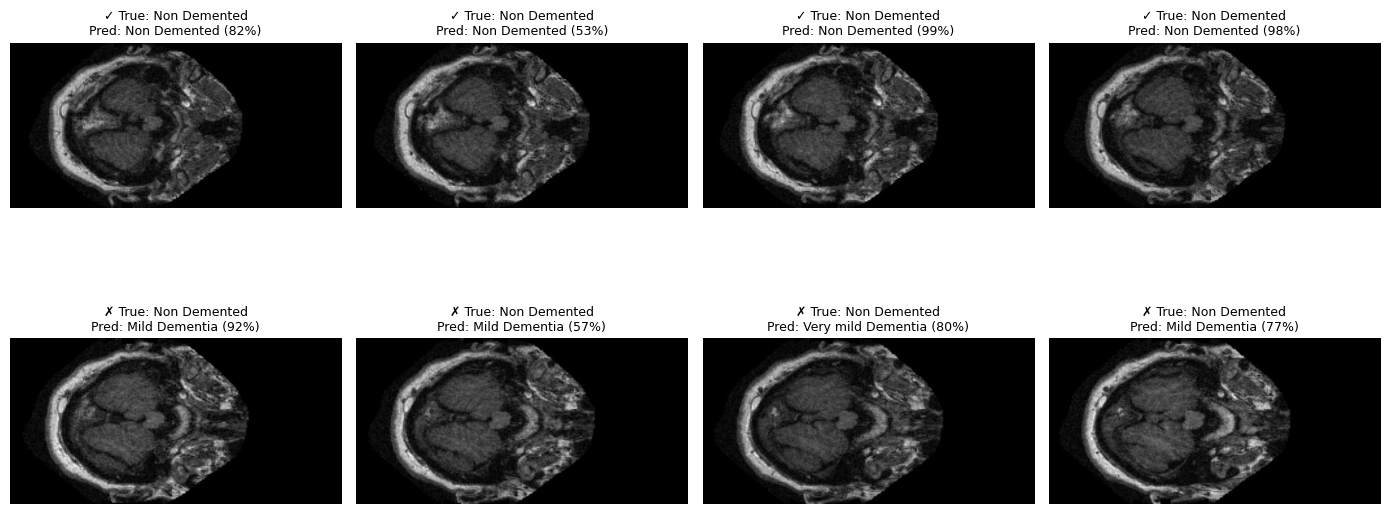

In [ ]:
import numpy as np, matplotlib.pyplot as plt
from PIL import Image

label_names = {0: "Mild Dementia", 1: "Moderate Dementia", 2: "Non Demented", 3: "Very mild Dementia"}
correct_idx   = np.where(y_pred == y_true)[0][:4]
incorrect_idx = np.where(y_pred != y_true)[0][:4]
idx_list = list(correct_idx) + list(incorrect_idx)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, idx in zip(axes.flat, idx_list):
    img  = Image.open(eval_df.iloc[idx]["path"]).convert("L")
    true = int(eval_df.iloc[idx]["label"])
    pred = int(y_pred[idx])
    prob = y_prob[idx, pred]
    mark = "✓" if pred == true else "✗"
    ax.imshow(img, cmap="gray")
    ax.set_title(f"{mark} True: {label_names[true]}\nPred: {label_names[pred]} ({prob:.0%})", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

In [26]:
import os, glob, zipfile, numpy as np, torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import ViTForImageClassification, ViTImageProcessor
from sklearn.metrics import f1_score, classification_report, confusion_matrix

# ---- config ----
CHECKPOINT_DIR = "/content/drive/MyDrive/vit_oasis"
ZIP_PATH    = None                 # None = auto-pick the .zip in /content
EXTRACT_DIR = "/content/cross_data"
OASIS_F1 = 0.342
BATCH = 32

# model head is ALPHABETICAL: 0=Mild, 1=Moderate, 2=Non, 3=VeryMild
# map each external folder to the model's index for that SAME class
FOLDER_TO_LABEL4 = {
    "NonDemented":      2,
    "VeryMildDemented": 3,
    "MildDemented":     0,
    "ModerateDemented": 1,
}
ALL_LABELS = [0, 1, 2, 3]
device = "cuda" if torch.cuda.is_available() else "cpu"

# ---- unzip ----
if ZIP_PATH is None:
    zips = glob.glob("/content/*.zip")
    assert zips, "No .zip found in /content"
    ZIP_PATH = max(zips, key=os.path.getsize)
print("unzipping:", ZIP_PATH)
os.makedirs(EXTRACT_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(EXTRACT_DIR)

# ---- locate the test split ----
def find_class_root(base, prefer="test"):
    targets = set(FOLDER_TO_LABEL4)
    cands = [dp for dp, dn, _ in os.walk(base) if targets & set(dn)]
    test_cands = [c for c in cands if prefer in c.lower()]
    return (test_cands or cands or [None])[0]

CROSS_TEST_DIR = find_class_root(EXTRACT_DIR)
assert CROSS_TEST_DIR, ("No class folders under " + EXTRACT_DIR +
    ":\n" + "\n".join(sorted({dp for dp,_,_ in os.walk(EXTRACT_DIR)})[:40]))
print("using test root:", CROSS_TEST_DIR)

# ---- model ----
try:
    proc = ViTImageProcessor.from_pretrained(CHECKPOINT_DIR)
except Exception:
    proc = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")
model = ViTForImageClassification.from_pretrained(CHECKPOINT_DIR).to(device).eval()
assert model.config.num_labels == 4
names = [model.config.id2label[i] for i in range(4)]
print("class order:", names)

# ---- data ----
class DS(Dataset):
    def __init__(self, root):
        self.s = []
        for f, lab in FOLDER_TO_LABEL4.items():
            d = os.path.join(root, f)
            if os.path.isdir(d):
                self.s += [(os.path.join(d, fn), lab) for fn in os.listdir(d)
                           if fn.lower().endswith((".jpg",".jpeg",".png"))]
        print(f"found {len(self.s)} images")
    def __len__(self): return len(self.s)
    def __getitem__(self, i):
        p, lab = self.s[i]
        pv = proc(images=Image.open(p).convert("RGB"), return_tensors="pt")["pixel_values"][0]
        return {"pixel_values": pv, "labels": lab}

loader = DataLoader(DS(CROSS_TEST_DIR), batch_size=BATCH, num_workers=2)

# ---- inference ----
preds, trues = [], []
with torch.no_grad():
    for b in loader:
        with torch.autocast(device_type="cuda", enabled=(device=="cuda")):
            logits = model(pixel_values=b["pixel_values"].to(device)).logits
        preds.append(logits.float().argmax(1).cpu().numpy())
        trues.append(np.asarray(b["labels"]))
y_pred, y_true = np.concatenate(preds), np.concatenate(trues)

# ---- metrics ----
cross_f1 = f1_score(y_true, y_pred, labels=ALL_LABELS, average="macro", zero_division=0)
drop = (cross_f1 - OASIS_F1) / OASIS_F1 * 100
print("\npred counts:", np.bincount(y_pred, minlength=4), "->", names)
print(confusion_matrix(y_true, y_pred, labels=ALL_LABELS))
print(classification_report(y_true, y_pred, labels=ALL_LABELS, target_names=names, zero_division=0))
print(f"\nCross-dataset Macro F1: {cross_f1:.3f}")
print(f"Drop vs OASIS ({OASIS_F1:.3f}): {drop:+.1f}%")
print(f"LaTeX row:  ViT-B/16 & {OASIS_F1:.3f} & {cross_f1:.3f} & ${drop:+.1f}\\%$ \\\\")

unzipping: /content/newdata.zip
using test root: /content/cross_data/Alzheimer_s Dataset/test


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

class order: ['Mild Dementia', 'Moderate Dementia', 'Non Demented', 'Very mild Dementia']
found 1279 images

pred counts: [   0 1274    5    0] -> ['Mild Dementia', 'Moderate Dementia', 'Non Demented', 'Very mild Dementia']
[[  0 179   0   0]
 [  0  12   0   0]
 [  0 640   0   0]
 [  0 443   5   0]]
                    precision    recall  f1-score   support

     Mild Dementia       0.00      0.00      0.00       179
 Moderate Dementia       0.01      1.00      0.02        12
      Non Demented       0.00      0.00      0.00       640
Very mild Dementia       0.00      0.00      0.00       448

          accuracy                           0.01      1279
         macro avg       0.00      0.25      0.00      1279
      weighted avg       0.00      0.01      0.00      1279


Cross-dataset Macro F1: 0.005
Drop vs OASIS (0.342): -98.6%
LaTeX row:  ViT-B/16 & 0.342 & 0.005 & $-98.6\%$ \\


In [27]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

print("id2label:", model.config.id2label)
print("true counts:", np.bincount(y_true, minlength=4))
print("pred counts:", np.bincount(y_pred, minlength=4))
print("\nconfusion (rows=true 0-3, cols=pred 0-3):")
print(confusion_matrix(y_true, y_pred, labels=[0,1,2,3]))
print()
print(classification_report(y_true, y_pred, labels=[0,1,2,3],
      target_names=["Non","VeryMild","Mild","Moderate"], zero_division=0))

id2label: {0: 'Mild Dementia', 1: 'Moderate Dementia', 2: 'Non Demented', 3: 'Very mild Dementia'}
true counts: [179  12 640 448]
pred counts: [   0 1274    5    0]

confusion (rows=true 0-3, cols=pred 0-3):
[[  0 179   0   0]
 [  0  12   0   0]
 [  0 640   0   0]
 [  0 443   5   0]]

              precision    recall  f1-score   support

         Non       0.00      0.00      0.00       179
    VeryMild       0.01      1.00      0.02        12
        Mild       0.00      0.00      0.00       640
    Moderate       0.00      0.00      0.00       448

    accuracy                           0.01      1279
   macro avg       0.00      0.25      0.00      1279
weighted avg       0.00      0.01      0.00      1279

